# INF201 - Deliverable 1: Weather data from Ås

**GitHub repository:** https://github.com/limmen20/handin1-inf201

In this notebook we get weather data from The Norwegian Meteorological Institute (MET)
through the Frost API (frost.met.no), and look at temperature, precipitation,
heatwaves and moving averages for the weather station in Ås (SN17850).

The code for getting data is based on the Python example from MET:
https://frost.met.no/python_example.html (we rewrote some parts of it).

## Setup

We import the packages we need. The client ID is stored in `api.txt`, which is
**not** part of the Git repository (it is listed in `.gitignore`), so the ID is never
committed.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yaml

In [2]:
def read_client_id(filename):
    """Read the Frost client ID from a text file."""
    with open(filename, 'r') as file:
        for line in file:
            if line.lower().startswith('client id'):
                return line.split(':')[1].strip()
    return None


CLIENT_ID = read_client_id('api.txt')
OBSERVATIONS_URL = 'https://frost.met.no/observations/v0.jsonld'
SOURCES_URL = 'https://frost.met.no/sources/v0.jsonld'
STATION_ID = 'SN17850'

Below is a helper function that we use for all the data requests. Frost sometimes
returns more than one value per day for the same element (with different
`timeOffset`, e.g. a day counted from 00:00 or from 06:00). To get only one value
per day we keep only the observations with the time offset we ask for.

Note: the end date in `referencetime` is *not* included, so to get all of 2025 we use
`2025-01-01/2026-01-01` (with `2025-12-31` as the end we would miss New Year's Eve).

In [3]:
def get_frost_data(source, element, start, end, time_offset='PT0H'):
    """Get daily observations from Frost and return them as a DataFrame.

    The DataFrame has two columns: 'date' and 'value'.
    Returns None if the request fails.
    """
    parameters = {
        'sources': source,
        'elements': element,
        'referencetime': f'{start}/{end}',
    }
    response = requests.get(OBSERVATIONS_URL, parameters,
                            auth=(CLIENT_ID, ''))
    json_data = response.json()

    if response.status_code != 200:
        print('Error! Returned status code', response.status_code)
        print('Message:', json_data['error']['message'])
        print('Reason:', json_data['error']['reason'])
        return None

    rows = []
    for item in json_data['data']:
        for observation in item['observations']:
            if observation['timeOffset'] == time_offset:
                rows.append({'date': item['referenceTime'][:10],
                             'value': observation['value']})

    df = pd.DataFrame(rows, columns=['date', 'value'])
    df['date'] = pd.to_datetime(df['date'])
    return df


def make_summary(datasets):
    """Make a summary table (mean, median, min, max) for one or more datasets.

    datasets is a dictionary where the key is the column name in the table
    and the value is a pandas Series with temperatures.
    """
    table = pd.DataFrame()
    for name, values in datasets.items():
        table[name] = [values.mean(), values.median(),
                       values.min(), values.max()]
    table.index = ['Mean (°C)', 'Median (°C)', 'Min (°C)', 'Max (°C)']
    return table.round(1)

## Task 1: Temperature

We request the daily mean air temperature for all of 2025.

In [4]:
temp_2025 = get_frost_data(STATION_ID, 'mean(air_temperature P1D)',
                           '2025-01-01', '2026-01-01')
temp_2025 = temp_2025.rename(columns={'value': 'temperature'})

print('Number of days:', len(temp_2025))
temp_2025.head()

Number of days: 365


,date,temperature
0,2025-01-01,-5.2
1,2025-01-02,-11.5
2,2025-01-03,-8.9
3,2025-01-04,-15.5
4,2025-01-05,-12.5


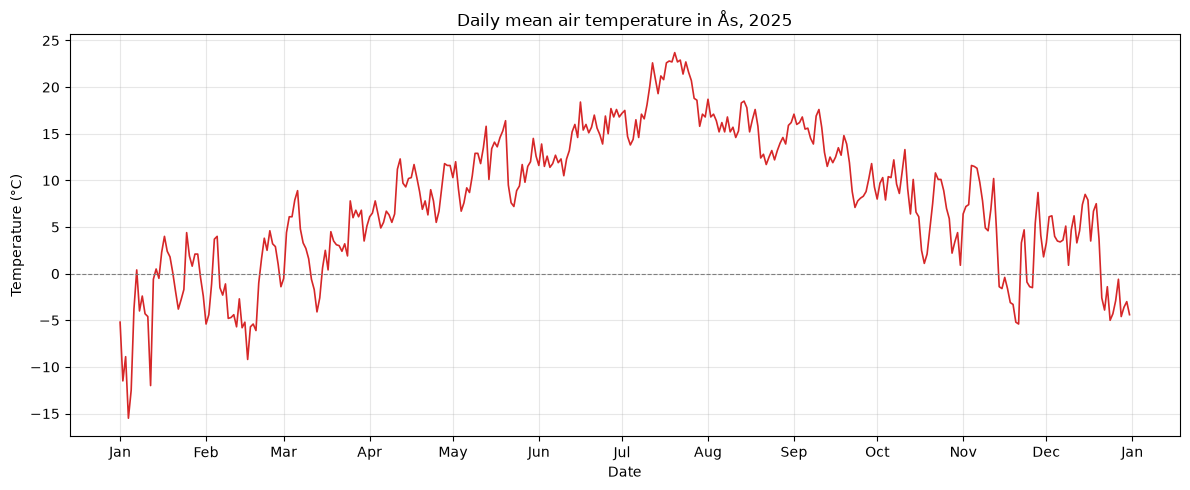

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_2025['date'], temp_2025['temperature'],
        color='tab:red', linewidth=1.2)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean air temperature in Ås, 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
summary_2025 = make_summary({'2025': temp_2025['temperature']})
print('Summary of daily mean temperature in Ås, 2025')
print(summary_2025.to_string())

Summary of daily mean temperature in Ås, 2025
             2025
Mean (°C)     7.9
Median (°C)   8.3
Min (°C)    -15.5
Max (°C)     23.7


**Discussion:** The temperature follows the seasons as expected: cold in January
and February, warmest in July, and then colder again towards December. The coldest day
was 4 January (-15.5 °C) and the warmest was 20 July (23.7 °C). The mean (7.9 °C) and
median (8.3 °C) are quite close, which means the temperatures are spread fairly evenly
around the middle. Note that these are daily *mean* values, so the warmest moment of a
day was higher than this (see task 4). Day-to-day changes are biggest in winter, where the
temperature can jump by more than 10 degrees in a few days.

## Task 2: Precipitation

We request the precipitation over 24 hours, `sum(precipitation_amount P1D)`.
For precipitation the standard in Norway is to measure from 06:00 to 06:00, so here we
use the observations with time offset `PT6H`.

Temperature is a value that changes smoothly over time, so we show it as a line.
Precipitation is an amount that has fallen during each day, so bars fit better.
The two measurements have different units, so we use two y-axes (one on each side)
with the same colour as the data they belong to.

In [7]:
precip_2025 = get_frost_data(STATION_ID, 'sum(precipitation_amount P1D)',
                             '2025-01-01', '2026-01-01', time_offset='PT6H')
precip_2025 = precip_2025.rename(columns={'value': 'precipitation'})

print('Number of days:', len(precip_2025))
print('Total precipitation in 2025:',
      round(precip_2025['precipitation'].sum(), 1), 'mm')

Number of days: 365
Total precipitation in 2025: 950.2 mm


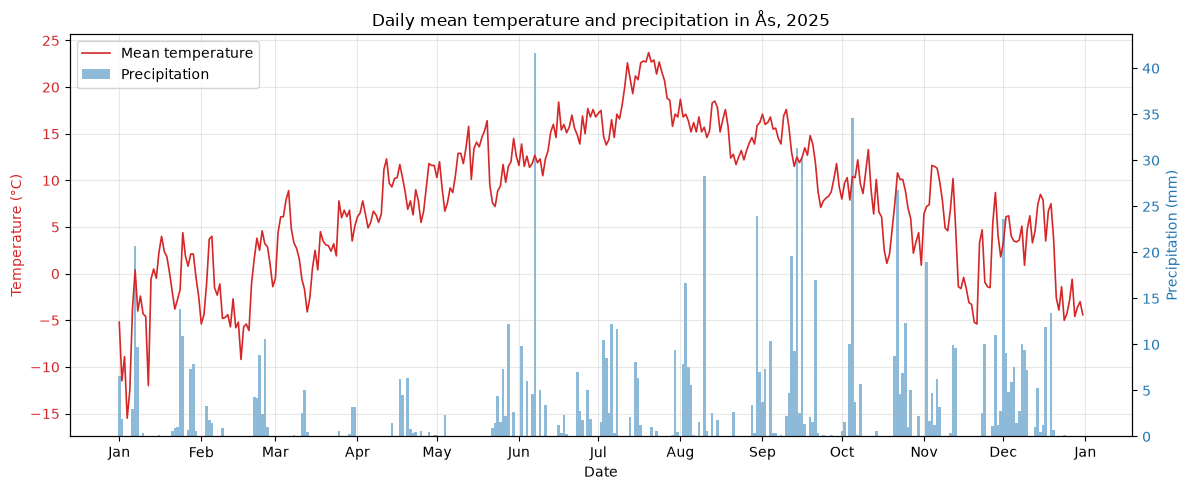

In [8]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Precipitation as bars on the right y-axis
ax2 = ax1.twinx()
ax2.bar(precip_2025['date'], precip_2025['precipitation'],
        width=1, color='tab:blue', alpha=0.5, label='Precipitation')
ax2.set_ylabel('Precipitation (mm)', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')

# Temperature as a line on the left y-axis, drawn on top of the bars
ax1.plot(temp_2025['date'], temp_2025['temperature'],
         color='tab:red', linewidth=1.2, label='Mean temperature')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

ax1.set_title('Daily mean temperature and precipitation in Ås, 2025')
ax1.set_xlabel('Date')
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax1.grid(alpha=0.3)

# One legend for both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

**Discussion:** In 2025 it rained or snowed on about half of the days
(184 of 365 days had more than 0 mm), and the total was about 950 mm. The wettest single
day was 7 June with 41.6 mm. The spring (March-May) was quite dry, while autumn
(September-October) was the wettest period with a lot of days with rain. Combining the
two in one plot makes it easy to see that the dry spring was also a period with rising
temperatures, and that there is no simple relation between temperature and
precipitation day to day.

## Task 3: Historical temperature data

We get the daily mean temperature from 1925, 100 years earlier, from the same station.
To plot both years on the same x-axis we move the 1925 dates forward by 100 years,
so that e.g. 1 March 1925 is plotted at the same place as 1 March 2025.

In [9]:
temp_1925 = get_frost_data(STATION_ID, 'mean(air_temperature P1D)',
                           '1925-01-01', '1926-01-01')
temp_1925 = temp_1925.rename(columns={'value': 'temperature'})

print('Number of days in 1925:', len(temp_1925))
temp_1925.head()

Number of days in 1925: 365


,date,temperature
0,1925-01-01,1.3
1,1925-01-02,4.1
2,1925-01-03,2.1
3,1925-01-04,0.1
4,1925-01-05,-2.2


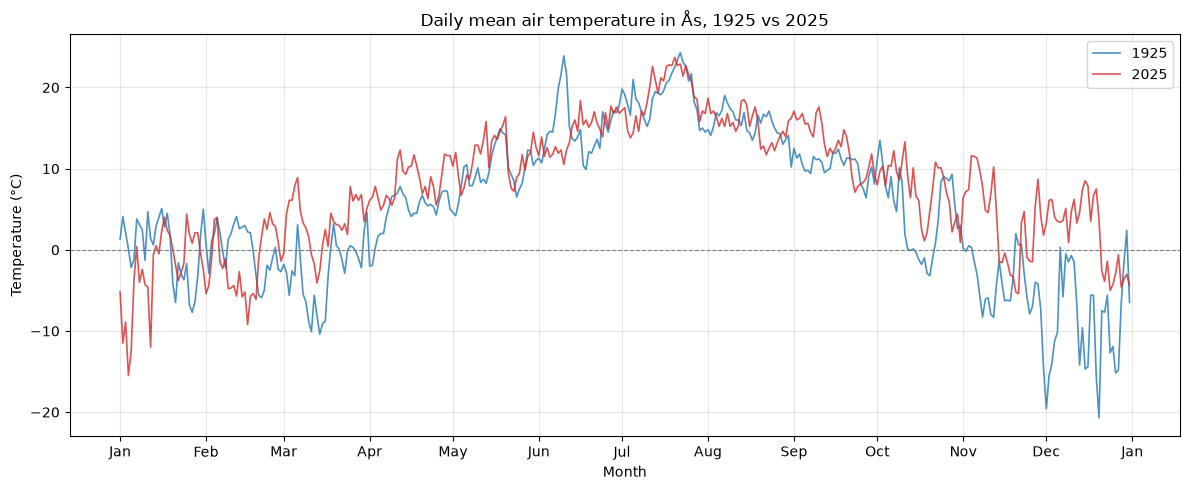

In [10]:
# Same day of the year, but in 2025, so the two years line up in the plot
temp_1925['plot_date'] = temp_1925['date'] + pd.DateOffset(years=100)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_1925['plot_date'], temp_1925['temperature'],
        color='tab:blue', linewidth=1.2, alpha=0.8, label='1925')
ax.plot(temp_2025['date'], temp_2025['temperature'],
        color='tab:red', linewidth=1.2, alpha=0.8, label='2025')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')

ax.set_title('Daily mean air temperature in Ås, 1925 vs 2025')
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [11]:
summary_both = make_summary({'1925': temp_1925['temperature'],
                             '2025': temp_2025['temperature']})
summary_both['Difference'] = summary_both['2025'] - summary_both['1925']
print('Summary of daily mean temperature in Ås, 1925 and 2025')
print(summary_both.to_string())

Summary of daily mean temperature in Ås, 1925 and 2025
             1925  2025  Difference
Mean (°C)     5.3   7.9         2.6
Median (°C)   5.3   8.3         3.0
Min (°C)    -20.7 -15.5         5.2
Max (°C)     24.3  23.7        -0.6


**Discussion:** 2025 was on average 2.6 °C warmer than 1925
(7.9 °C vs 5.3 °C). The summers are very similar (June-August have almost the same monthly
mean), and 1925 actually had a slightly warmer maximum day. The big difference is in the
cold part of the year: November and December 1925 were much colder than in 2025
(about 8 and 11 degrees colder in monthly mean), and 1925 had 111 days with mean
temperature below 0 °C compared to 65 in 2025. This fits with what is known about climate
change in Norway, where winters have become warmer. But this is only two single years, and
the weather can vary a lot from one year to another, so we can not say much about long term
trends from just these two years. To do that we would need to compare averages over many
years. The station has also been changed and moved over time, which can affect the
measurements a bit.

## Task 4: Heatwaves

In Norway a heatwave is a period of at least five days in a row where the
**max** temperature is 27 °C or more. We therefore use `max(air_temperature P1D)`.

First we write a small function that finds the station ID and name, so that the
heatwave function works with either a station ID (like `'SN17850'`) or a
station name (like `'Ås'`).

In [12]:
def get_station_info(station):
    """Return the station id and name from either a station id or a name."""
    if station.upper().startswith('SN') and station[2:].isdigit():
        parameters = {'ids': station.upper()}
    else:
        parameters = {'name': station}

    response = requests.get(SOURCES_URL, parameters, auth=(CLIENT_ID, ''))
    if response.status_code != 200:
        raise ValueError(f'Could not find a station called {station}')

    first_match = response.json()['data'][0]
    # shortName is the nicer name ('Ås' instead of 'ÅS'), but not all have it
    station_name = first_match.get('shortName', first_match['name'])
    return first_match['id'], station_name

In [13]:
def count_heatwaves(station, year, min_temp=27, min_days=5, filename=None):
    """Count the heatwaves for a station in a given year.

    A heatwave is at least min_days days in a row with max temperature
    >= min_temp. A summary is written to a yml file and the number of
    heatwaves is returned.
    """
    station_id, station_name = get_station_info(station)
    max_temp = get_frost_data(station_id, 'max(air_temperature P1D)',
                              f'{year}-01-01', f'{year + 1}-01-01')
    if max_temp is None or len(max_temp) == 0:
        print(f'No max temperature data for {station_name} in {year}')
        return None

    heatwaves = []
    streak = []  # the hot days in a row we are counting right now
    for date, temp in zip(max_temp['date'], max_temp['value']):
        is_next_day = len(streak) > 0 and (date - streak[-1]).days == 1

        if temp >= min_temp and (len(streak) == 0 or is_next_day):
            streak.append(date)
        else:
            # The streak is over, save it if it was long enough
            if len(streak) >= min_days:
                heatwaves.append((streak[0], streak[-1]))
            if temp >= min_temp:
                streak = [date]  # a hot day after a gap in the data
            else:
                streak = []

    # In case the year ends during a heatwave
    if len(streak) >= min_days:
        heatwaves.append((streak[0], streak[-1]))

    summary = {
        'dates': [f'{start:%Y-%m-%d} - {end:%Y-%m-%d}'
                  for start, end in heatwaves],
        'station_id': station_id,
        'station_name': station_name,
        'year': year,
    }
    if filename is None:
        filename = f'heatwave_summary_{station_id}_{year}.yml'
    with open(filename, 'w') as file:
        yaml.dump(summary, file)

    return len(heatwaves)

In [14]:
number_of_heatwaves = count_heatwaves('Ås', 2025,
                                      filename='heatwave_summary.yml')
print('Number of heatwaves in Ås in 2025:', number_of_heatwaves)
print()

with open('heatwave_summary.yml', 'r') as file:
    print(file.read())

Number of heatwaves in Ås in 2025: 1

dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



To check that the function works for other stations and years, we also try it with
a station ID and a different year:

In [15]:
for station, year in [('SN17850', 2018), ('SN18700', 2025)]:
    n = count_heatwaves(station, year)
    print(f'{station}, {year}: {n} heatwave(s)')

SN17850, 2018: 1 heatwave(s)


SN18700, 2025: 1 heatwave(s)


**Discussion:** We found **one heatwave in Ås in 2025**, from 16 to 20 July
(exactly five days in a row with max temperature of 27 °C or more, with the highest at 30.8 °C).
On 21 July the max temperature was 26.5 °C, which breaks the streak, even though the days
right after were also hot. This shows that the definition is quite strict: a single day
just under 27 °C stops the heatwave. Note that the dates in the example yml file
are only an example and not the real result. The function also works with a station ID and
other years, e.g. for Ås in 2018 it finds the heatwave from 29 May to 3 June. In the
function we also check that the hot days really are next to each other in time, so that a
missing day in the data does not get counted as part of a heatwave.

## Task 5: Moving average temperature

We write our own function for the 7-day moving average. For each day we take the
average of that day and the 6 days before it. The first 6 days do not have enough
days before them, so they get `NaN` (no value).

In [16]:
def moving_average(values, window=7):
    """Calculate the moving average of a list of values.

    Each average uses the current value and the (window - 1) values before
    it. The first (window - 1) positions get NaN.
    """
    values = list(values)
    averages = []
    for i in range(len(values)):
        if i < window - 1:
            averages.append(float('nan'))
        else:
            window_values = values[i - window + 1:i + 1]
            averages.append(sum(window_values) / window)
    return averages


temp_2025['moving_avg_7'] = moving_average(temp_2025['temperature'])

# Check our function against the built-in pandas version
pandas_version = temp_2025['temperature'].rolling(7).mean()
print('Same result as pandas:',
      ((temp_2025['moving_avg_7'] - pandas_version).abs().max() < 1e-9))
temp_2025.head(10)

Same result as pandas: True


,date,temperature,moving_avg_7
0,2025-01-01,-5.2,NaN
1,2025-01-02,-11.5,NaN
2,2025-01-03,-8.9,NaN
3,2025-01-04,-15.5,NaN
4,2025-01-05,-12.5,NaN
5,2025-01-06,-3.8,NaN
6,2025-01-07,0.4,-8.142857
7,2025-01-08,-4.0,-7.971429
8,2025-01-09,-2.4,-6.671429
9,2025-01-10,-4.3,-6.014286


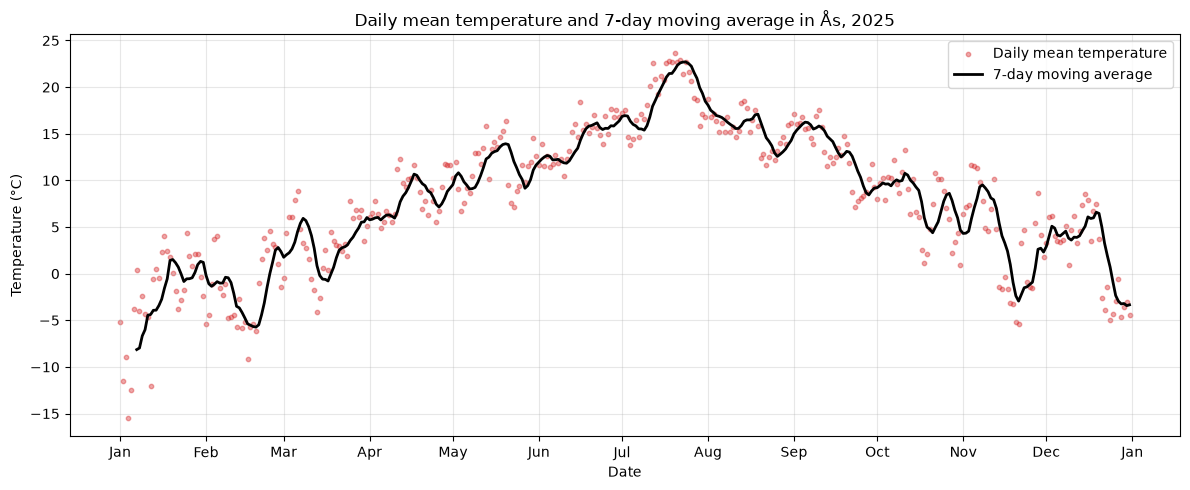

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(temp_2025['date'], temp_2025['temperature'],
           s=10, color='tab:red', alpha=0.4, label='Daily mean temperature')
ax.plot(temp_2025['date'], temp_2025['moving_avg_7'],
        color='black', linewidth=2, label='7-day moving average')

ax.set_title('Daily mean temperature and 7-day moving average in Ås, 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

**Discussion:** The 7-day moving average smooths out the day-to-day
variation, so it is easier to see the overall trend over the year and longer cold or warm
periods (for example the warm period in mid/late July and the cold spell in late November).
The single daily points spread a lot around the line, especially in winter. Since we use the
current day and the 6 days before it, the line is a bit "late" compared to the data, and
the first 6 days have no value. A centered moving average (3 days before and 3 after) would
avoid the lag, but then the last 3 days would not have a value instead. Our own function
gives the same result as the pandas function `rolling(7).mean()`.

## Use of generative AI

We wrote a first draft of the code and the discussion ourselves, then used Claude (Anthropic) to help improve it. Claude helped clean up the code so it follows the PEP 8 style guide more closely, with clearer variable names, docstrings and a more consistent structure. It also helped with parts of the code and logic where we got stuck. One example is the heatwave function, where it helped us make sure hot days are actually consecutive. It also helped with the plot that shows temperature and precipitation on two y-axes. It suggested small improvements to the wording of the markdown explanations as well. We went through all the suggestions, kept the ones we understood and agreed with, and ran the notebook ourselves to check that the code and results were correct.